# Question 2: Topic modelling of the news files
Run the cells from top to bottom. The notebook must be opened from the Q2 folder.

In [6]:
# The below need to run first

library(tm)
library(topicmodels)
library(ggplot2)
library(wordcloud)

## Q2.1 Build the data frame and denoise the text

In [7]:
data_dir <- "../datasets/sa_news"
files <- list.files(data_dir, pattern = "\\.txt$", full.names = TRUE)
if (length(files) == 0) stop("No .txt files found. setwd() to the Q2 folder first.")
files <- files[order(as.numeric(gsub("\\D", "", basename(files))))]

news_df <- data.frame(
  file_name = basename(files),
  content   = sapply(files, function(f) paste(readLines(f, warn = FALSE, encoding = "UTF-8"), collapse = " ")),
  stringsAsFactors = FALSE
)
rownames(news_df) <- NULL

# words that carry no topic information in these articles
noise <- c(stopwords("en"), "said", "also", "will", "may", "sanews", "south", "africa",
           "african", "including", "expected", "gov",
           month.name, tolower(month.name), "monday", "tuesday", "wednesday", "thursday", "friday",
           "saturday", "sunday")

denoise <- function(text) {
  text <- tolower(text)
  text <- gsub("[^a-z ]", " ", text)            # keep letters only (removes numbers and punctuation)
  words <- strsplit(text, "\\s+")[[1]]
  words <- words[nchar(words) > 2 & !(words %in% noise)]
  paste(words, collapse = " ")
}
news_df$denoised <- sapply(news_df$content, denoise)

# show the start of each article before and after denoising
print(data.frame(file_name = news_df$file_name,
                 content   = substr(news_df$content, 1, 60),
                 denoised  = substr(news_df$denoised, 1, 60)))
write.csv(news_df, "Q2_1_dataframe.csv", row.names = FALSE)

     file_name                                                      content
1   news_1.txt Eskom former official, service provider appear in court Tues
2   news_2.txt Gauteng Education commits to implementing Mayibuye Primary S
3   news_3.txt New Labour Minister charts the way forward  Tuesday, July 9,
4   news_4.txt Police recue two kidnapped victims in Benoni Tuesday, July 9
5   news_5.txt President Ramaphosa sends condolences to deceased SANDF memb
6   news_6.txt Accounting officers must be accountable for non-payment of s
7   news_7.txt Democratic dispensation necessitated a complete overhaul of 
8   news_8.txt Trust and relationships key ingredients to coalition governm
9   news_9.txt PSC applauds officials who refuse to accept a bribes Monday,
10 news_10.txt Wet, cold weather expected to continue in Western Cape Monda
                                                       denoised
1  eskom former official service provider appear court eskom fo
2  gauteng education commits impleme

## Q2.2 LDA topic model: top-k words and word distribution

In [8]:
corpus <- VCorpus(VectorSource(news_df$denoised))
dtm <- DocumentTermMatrix(corpus)
dtm <- dtm[, colSums(as.matrix(dtm)) >= 2]       # drop words that appear only once

k <- 3          # number of topics
top_k <- 10     # words shown per topic
lda <- LDA(dtm, k = k, method = "Gibbs", control = list(seed = 1234, burnin = 500, iter = 2000))

word_dist <- posterior(lda)$terms                # topic x word probabilities
doc_dist  <- posterior(lda)$topics               # document x topic probabilities

top_terms <- do.call(rbind, lapply(1:k, function(t) {
  p <- sort(word_dist[t, ], decreasing = TRUE)[1:top_k]
  data.frame(topic = paste("Topic", t), word = names(p), probability = round(as.numeric(p), 4))
}))
print(top_terms)

doc_topics <- data.frame(file_name = news_df$file_name, round(doc_dist, 3))
colnames(doc_topics)[-1] <- paste("Topic", 1:k)
doc_topics$main_topic <- paste("Topic", apply(doc_dist, 1, which.max))
print(doc_topics)

write.csv(top_terms, "Q2_2_top_words.csv", row.names = FALSE)
write.csv(doc_topics, "Q2_2_document_topics.csv", row.names = FALSE)

     topic           word probability
1  Topic 1          eskom      0.0270
2  Topic 1         police      0.0248
3  Topic 1     department      0.0225
4  Topic 1           cape      0.0181
5  Topic 1           cold      0.0158
6  Topic 1        weather      0.0158
7  Topic 1           west      0.0158
8  Topic 1        western      0.0158
9  Topic 1          sandf      0.0136
10 Topic 1        service      0.0136
11 Topic 2       invoices      0.0313
12 Topic 2         public      0.0294
13 Topic 2        service      0.0294
14 Topic 2           days      0.0255
15 Topic 2            psc      0.0235
16 Topic 2        gxoyiya      0.0216
17 Topic 2    departments      0.0196
18 Topic 2         report      0.0196
19 Topic 2     management      0.0177
20 Topic 2      officials      0.0138
21 Topic 3     government      0.0356
22 Topic 3     department      0.0250
23 Topic 3      coalition      0.0232
24 Topic 3       national      0.0232
25 Topic 3 administration      0.0215
26 Topic 3  

## Q2.3 Visualisations

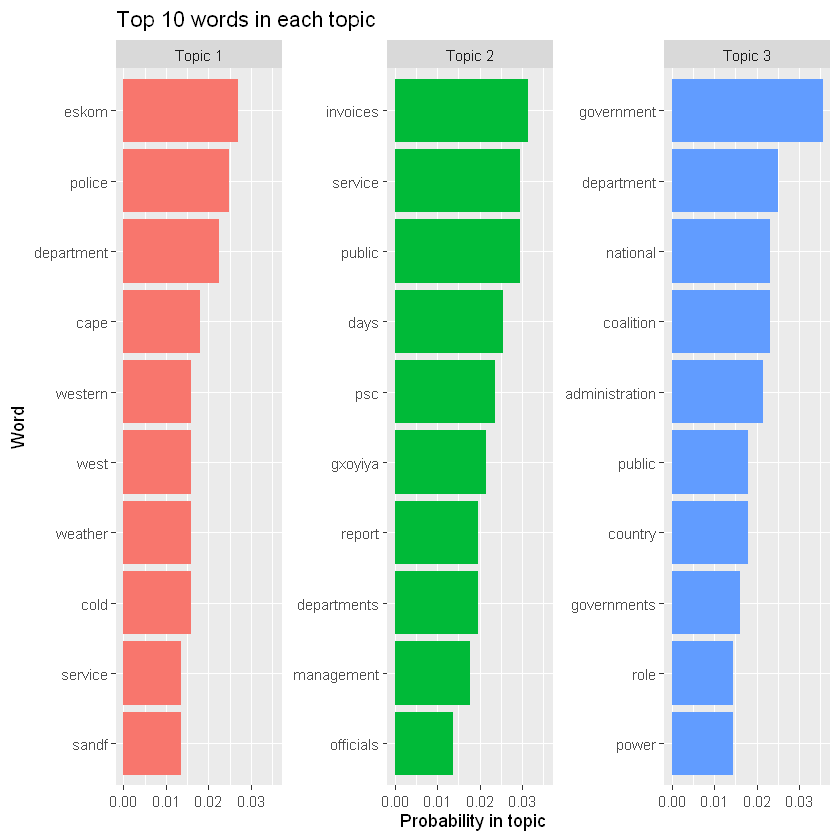

In [9]:
# Visualisation 1: top words of each topic (bar chart)
top_terms$label <- reorder(paste(top_terms$topic, top_terms$word, sep = "__"), top_terms$probability)
bar_chart <- ggplot(top_terms, aes(x = label, y = probability, fill = topic)) +
  geom_col(show.legend = FALSE) +
  scale_x_discrete(labels = function(x) sub("^.*__", "", x)) +
  coord_flip() +
  facet_wrap(~ topic, scales = "free_y") +
  labs(title = "Top 10 words in each topic", x = "Word", y = "Probability in topic")
ggsave("Q2_3_bar_chart.png", bar_chart, width = 10, height = 5, dpi = 150)
print(bar_chart)

pdf 
  2

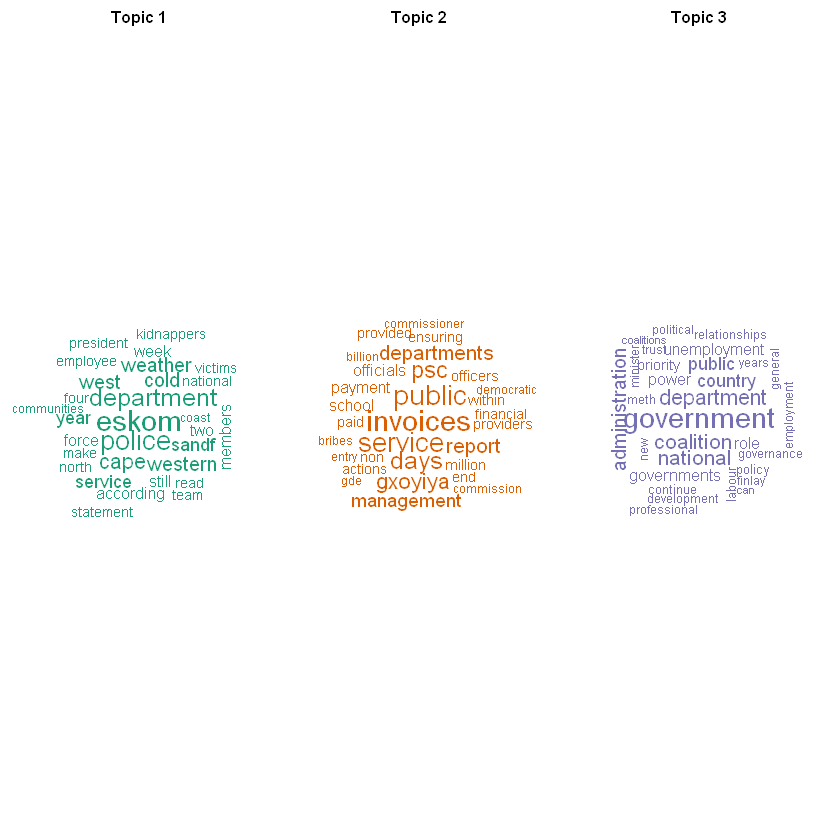

In [10]:
# Visualisation 2: word clouds, one per topic
png("Q2_3_wordclouds.png", width = 1500, height = 500, res = 130)
par(mfrow = c(1, k), mar = c(0, 0, 2, 0))
for (t in 1:k) {
  p <- sort(word_dist[t, ], decreasing = TRUE)[1:30]
  wordcloud(names(p), p, scale = c(2.2, 0.5), random.order = FALSE, colors = c("#1B9E77", "#D95F02", "#7570B3")[t])
  title(paste("Topic", t))
}
dev.off()

# show the word clouds in the notebook / plot window as well
par(mfrow = c(1, k), mar = c(0, 0, 2, 0))
for (t in 1:k) {
  p <- sort(word_dist[t, ], decreasing = TRUE)[1:30]
  wordcloud(names(p), p, scale = c(2.2, 0.5), random.order = FALSE, colors = c("#1B9E77", "#D95F02", "#7570B3")[t])
  title(paste("Topic", t))
}